# Projet final — Assistant de révision de contrats (LEDGAR)

Cœur NLP d'un assistant de révision de contrats (legal-tech) : classification de clauses par type fine-tuning BERT, index de recherche sémantique, audit des biais.

**Données** : LEDGAR (benchmark LexGLUE) — 60k/10k/10k clauses, 100 types, anglais.
**Modèles** : `bert-base-uncased` (classification) · `all-MiniLM-L6-v2` (recherche).
**Énoncé** : `sujet.md` · **Résultats** : voir README (accuracy test 84,7 %, F1 macro 73,9 %).

## 1. Exploration des données

Charger LEDGAR, compter les classes, mesurer les longueurs : comprendre les données conditionne tous les choix ultérieurs (modèle, métriques, `max_length`).

In [1]:
#!import datasets 
from datasets import load_dataset
import numpy as np

ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
names = ledgar["train"].features["label"].names
print(ledgar)

counts = np.bincount(ledgar["train"]["label"], minlength=len(names))
print(names[counts.argmax()], counts.max(), "|", names[counts.argmin()], counts.min())
texts = list(ledgar["train"]["text"])


DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 60000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
    validation: Dataset({
        features: ['text', 'label'],
        num_rows: 10000
    })
})
Governing Laws 3167 | Books 23


### 1.1 Distribution des 100 classes

Déséquilibre fort : ~140:1 entre `Governing Laws` (3 167) et `Books` (23). 11 classes < 200 exemples, 3 < 100. Ce constat oriente le choix des métriques (F1 macro) et fournira la trame de l'audit des biais.

In [2]:
for i in np.argsort(counts)[::-1][:20]:   # top 20 classes
    print(f"{names[i]:<25} {counts[i]:>5} {'█' * (counts[i] // 100)}")

Governing Laws             3167 ███████████████████████████████
Notices                    2493 ████████████████████████
Counterparts               2427 ████████████████████████
Entire Agreements          2340 ███████████████████████
Severability               1808 ██████████████████
Survival                   1469 ██████████████
Amendments                 1467 ██████████████
Assignments                1327 █████████████
Expenses                   1224 ████████████
Terms                      1166 ███████████
Terminations               1112 ███████████
Insurances                 1104 ███████████
Taxes                      1089 ██████████
Litigations                1034 ██████████
Confidentiality            1012 ██████████
Further Assurances         1009 ██████████
General                     976 █████████
Compliance With Laws        960 █████████
Indemnifications            936 █████████
Waivers                     878 ████████


In [ ]:
for i in np.argsort(counts)[::-1][-20:]:   # bottom 20 classes
    print(f"{names[i]:<25} {counts[i]:>5} {'█' * (counts[i] // 100)}")

Disability                  263 ██
Existence                   258 ██
Modifications               255 ██
Agreements                  252 ██
Enforceability              244 ██
Submission To Jurisdiction   238 ██
Effectiveness               229 ██
Jurisdictions               202 ██
Enforcements                201 ██
Positions                   190 █
Approvals                   178 █
Consent To Jurisdiction     175 █
Costs                       168 █
Venues                      131 █
Powers                      125 █
Sanctions                   118 █
Anti-Corruption Laws        106 █
Qualifications               47 
Assigns                      31 
Books                        23 


Matplotlib is building the font cache; this may take a moment.


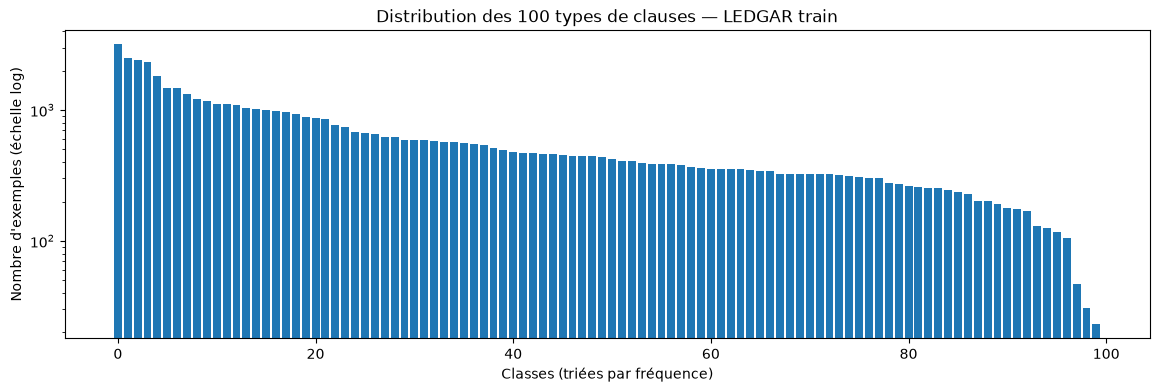

In [4]:
import matplotlib.pyplot as plt

order = np.argsort(counts)[::-1]
plt.figure(figsize=(14, 4))
plt.bar(range(len(counts)), counts[order])
plt.yscale("log")        # indispensable vu le rapport 140:1
plt.xlabel("Classes (triées par fréquence)")
plt.ylabel("Nombre d'exemples (échelle log)")
plt.title("Distribution des 100 types de clauses — LEDGAR train")
plt.show()

In [5]:
print((counts < 200).sum(), "classes < 200 exemples")
print((counts < 100).sum(), "classes < 100 exemples")

11 classes < 200 exemples
3 classes < 100 exemples


### 1.2 Baseline et tokenisation

**Baseline** : toujours prédire la classe majoritaire (~5,8 % sur le test) — le plancher en dessous duquel un modèle n'a aucune valeur.

**Tokenisation** : le tokenizer de `bert-base-uncased` mesure la longueur réelle des clauses en tokens pour choisir `max_length` (limite BERT : 512).

In [6]:
# prédire toujours la classe majoritaire sur le test
major = counts.argmax()
acc = (np.array(ledgar["test"]["label"]) == major).mean()
print(f"Baseline majoritaire : accuracy = {acc:.3f}")

Baseline majoritaire : accuracy = 0.058


In [7]:
from transformers import AutoTokenizer
tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")

enc = tokenizer(texts[:3], truncation=True, max_length=128, return_length=True)
print(enc["length"])   # longueurs en tokens → valide ton choix de max_length

[75, 90, 63]


In [8]:
sample = list(ledgar["train"].select(range(2000))["text"])

enc = tokenizer(sample, truncation=True, max_length=512, return_length=True)
lengths = np.array(enc["length"])
print(np.percentile(lengths, [50, 90, 95, 99, 100]))

[109.  298.  385.1 512.  512. ]


In [9]:
print(type(sample), type(sample[0]), len(sample))

<class 'list'> <class 'str'> 2000


**Choix retenu : `max_length=256`.** Percentiles mesurés sur 2 000 clauses : p50=109, p90=298, p95=385, p99=512. 256 tronque ~15 % des clauses ; l'information de type est généralement portée par le début de la clause. Compromis coût/précision (l'attention est en O(n²)) ; le padding sera dynamique, batch par batch.

## 2. Fine-tuning BERT (missions 1 & 2)

### 2.1 Pipeline d'entraînement

Tokenisation des splits (`dataset.map`, troncature à 256, pas de padding à cette étape), modèle (`AutoModelForSequenceClassification`, tête 100 classes neuve), padding dynamique (`DataCollatorWithPadding`), hyperparamètres et `Trainer`.

**Stratégie** : d'abord un mini-test local (2 000 clauses, 1 epoch, CPU) pour valider le pipeline, puis l'entraînement complet sur Colab (T4 GPU) : 60k clauses, 2 epochs, batch 16, lr 2e-5 — résultats : accuracy 84,4 % / F1 macro 73,9 % en validation.

In [10]:
def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=256)

tokenized = ledgar.map(tokenize, batched=True)
small_train = tokenized["train"].shuffle(seed=42).select(range(2000))
small_val   = tokenized["validation"].shuffle(seed=42).select(range(500))
print(small_train, small_val)

# puis Trainer avec ces petits datasets — 10-15 min sur CPU, et tu sais si tout marche

Map:   0%|          | 0/60000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 2000
}) Dataset({
    features: ['text', 'label', 'input_ids', 'token_type_ids', 'attention_mask'],
    num_rows: 500
})


In [11]:
from transformers import (AutoModelForSequenceClassification,
                          DataCollatorWithPadding, Trainer, TrainingArguments)
import evaluate

model = AutoModelForSequenceClassification.from_pretrained(
    "bert-base-uncased", num_labels=100
)

collator = DataCollatorWithPadding(tokenizer=tokenizer)

acc_m, f1_m = evaluate.load("accuracy"), evaluate.load("f1")

def compute_metrics(pred):
    preds = pred.predictions.argmax(-1)
    return {
        "accuracy": acc_m.compute(predictions=preds, references=pred.label_ids)["accuracy"],
        "f1_macro": f1_m.compute(predictions=preds, references=pred.label_ids, average="macro")["f1"],
    }

args = TrainingArguments(
    output_dir="runs/bert-ledgar-small",
    learning_rate=2e-5,
    per_device_train_batch_size=8,      # CPU : 8 est plus sûr que 16
    num_train_epochs=1,                 # test de pipeline : 1 epoch suffit
    eval_strategy="epoch",
    save_strategy="epoch",
    logging_steps=20,
    report_to="none",                   # évite l'installation de wandb/tensorboard
)

trainer = Trainer(
    model=model, args=args,
    train_dataset=small_train, eval_dataset=small_val,
    data_collator=collator, compute_metrics=compute_metrics,
)
trainer.train()

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertForSequenceClassification LOAD REPORT from: bert-base-uncased
Key                                        | Status     | 
-------------------------------------------+------------+-
cls.predictions.transform.dense.bias       | UNEXPECTED | 
cls.seq_relationship.weight                | UNEXPECTED | 
cls.predictions.bias                       | UNEXPECTED | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED | 
cls.predictions.transform.dense.weight     | UNEXPECTED | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED | 
cls.seq_relationship.bias                  | UNEXPECTED | 
classifier.weight                          | MISSING    | 
classifier.bias                            | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


/Users/charles/Documents/Projets/Projet_Deep_Learning/Python_Charles_projet_deep_learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,4.125383,4.113748,0.190000,0.028354


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=250, training_loss=4.335668975830078, metrics={'train_runtime': 410.5098, 'train_samples_per_second': 4.872, 'train_steps_per_second': 0.609, 'total_flos': 246241759451904.0, 'train_loss': 4.335668975830078, 'epoch': 1.0})

### 2.2 Mini-test local (validation du pipeline)

Évaluation du petit modèle (2 000 clauses) : accuracy 21,2 %, F1 macro 3,9 % — modeste mais attendu avec 20 exemples moyens par classe. L'écart accuracy/F1 macro matérialise déjà le déséquilibre.

_Note : la cellule suivante (`trainer.predict`) a servi à révéler un mauvais chargement de modèle (résultats identiques au mini-test) — voir 3.1._

In [12]:
pred = trainer.predict(tokenized["test"])
print(pred.metrics)   # test_accuracy, test_f1_macro

/Users/charles/Documents/Projets/Projet_Deep_Learning/Python_Charles_projet_deep_learning/.venv/lib/python3.12/site-packages/torch/utils/data/dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but not supported on MPS now, device pinned memory won't be used.
  super().__init__(loader)


{'test_loss': 4.108649253845215, 'test_accuracy': 0.1911, 'test_f1_macro': 0.024133453198058093, 'test_runtime': 398.175, 'test_samples_per_second': 25.115, 'test_steps_per_second': 3.139}


## 3. Évaluation sur le jeu de test

Chargement du checkpoint fine-tuné (`bert-ledgar/`, non versionné — voir README) et évaluation sur les 10 000 clauses de test, jamais vues pendant l'entraînement.

_Leçon de débogage : un premier `predict` avait donné les résultats du mini-test (~22 %) — le `Trainer` obsolète était resté en mémoire. D'où le rechargement explicite et le sanity check ci-dessous avant toute inférence longue._

In [13]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification

tokenizer = AutoTokenizer.from_pretrained("bert-ledgar")
model = AutoModelForSequenceClassification.from_pretrained("bert-ledgar")


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

In [14]:
print("num_labels =", model.config.num_labels)

num_labels = 100


### 3.1 Sanity check

Avant toute inférence longue : vérifier sur 100 clauses de validation que le checkpoint chargé prédit au niveau attendu (~0,8). 2 minutes de contrôle évitent 50 minutes d'inférence dans le vide.

In [15]:
from datasets import load_dataset
import torch

torch.set_num_threads(8)
ledgar = load_dataset("coastalcph/lex_glue", "ledgar")
sample_val = ledgar["validation"].select(range(100))

enc = tokenizer(list(sample_val["text"]), truncation=True, max_length=256,
                padding=True, return_tensors="pt")
with torch.no_grad():
    logits = model(**enc).logits
acc = (logits.argmax(-1).numpy() == sample_val["label"]).mean()
print(f"Sanity check : accuracy = {acc:.2f} sur 100 clauses")

Sanity check : accuracy = 0.78 sur 100 clauses


### 3.2 Prédiction sur le jeu de test

Inférence par batches sur les 10 000 clauses de test (batch 64, padding par batch, sauvegarde des prédictions en `.npy` pour ne jamais refaire le calcul).

In [16]:
import numpy as np
import torch, time

torch.set_num_threads(8)

# Split de test, noms sans ambiguïté ( texts = train dans la cellule 0 !)
test = ledgar["test"]
test_texts = list(test["text"])        # 10 000 clauses
y_true = np.array(test["label"])       # étiquettes réelles
n = len(test_texts)                    # 10 000
print(n, "clauses de test")

preds = []
B = 64
t0 = time.time()

for i in range(0, n, B):
    batch_texts = test_texts[i:i+B]    # ← test_texts, pas texts
    enc = tokenizer(batch_texts, truncation=True, max_length=256,
                    padding=True, return_tensors="pt")
    with torch.no_grad():
        preds.append(model(**enc).logits.argmax(-1).numpy())

    done = min(i + B, n)
    elapsed = time.time() - t0
    speed = done / elapsed
    eta = (n - done) / speed
    print(f"\r{done}/{n} clauses ({done/n:6.1%}) — "
          f"{speed:5.1f} clauses/s — ETA {eta/60:4.1f} min", end="", flush=True)

print()

y_pred = np.concatenate(preds)
np.save("test_preds.npy", y_pred)
np.save("test_labels.npy", y_true)
acc = (y_pred == y_true).mean()
print(f"Test accuracy : {acc:.4f}")

10000 clauses de test
10000/10000 clauses (100.0%) —  13.7 clauses/s — ETA  0.0 min
Test accuracy : 0.8473


## 4. Audit des biais (mission 4)

Objectif : chiffrer **là où le modèle est fiable et là où il ne l'est pas** — F1 par classe, pires classes croisées avec les effectifs d'entraînement, confusions systématiques.

In [17]:
from sklearn.metrics import classification_report, f1_score
import numpy as np

y_pred = np.load("test_preds.npy")
y_true = np.load("test_labels.npy")

print(classification_report(y_true, y_pred, target_names=names, zero_division=0))

f1s = f1_score(y_true, y_pred, average=None, zero_division=0)
worst = np.argsort(f1s)[:15]
print("\n=== 15 classes aux plus faibles F1 ===")
for i in worst:
    print(f"{names[i]:<30} F1={f1s[i]:.2f}  (support test={np.sum(y_true==i)}, "
          f"train={counts[i]})")

                              precision    recall  f1-score   support

                 Adjustments       0.90      0.91      0.90        88
                  Agreements       0.87      0.27      0.41        48
                  Amendments       0.79      0.93      0.85       224
        Anti-Corruption Laws       0.96      0.96      0.96        23
             Applicable Laws       0.00      0.00      0.00        53
                   Approvals       0.50      0.38      0.43        26
                 Arbitration       0.87      0.98      0.92        47
                 Assignments       0.84      0.90      0.87       195
                     Assigns       0.00      0.00      0.00         4
                   Authority       0.53      0.68      0.60        62
              Authorizations       0.69      0.62      0.65        90
                 Base Salary       0.96      0.97      0.97       112
                    Benefits       0.89      0.72      0.79        81
             Bindin

In [18]:
from sklearn.metrics import confusion_matrix
import numpy as np

cm = confusion_matrix(y_true, y_pred)
np.fill_diagonal(cm, 0)              # on masque les diagonales (bons cas)
top_conf = np.dstack(np.unravel_index(np.argsort(cm.ravel())[::-1][:15], cm.shape))[0]
print("=== Top 15 confusions (vraie → prédite) ===")
for t, p in top_conf:
    print(f"{names[t]:<28} → {names[p]:<28} ({cm[t, p]} fois)")

=== Top 15 confusions (vraie → prédite) ===
Tax Withholdings             → Withholdings                 (71 fois)
Applicable Laws              → Governing Laws               (45 fois)
Defined Terms                → Definitions                  (40 fois)
Integration                  → Entire Agreements            (31 fois)
Successors                   → Binding Effects              (26 fois)
Taxes                        → Withholdings                 (26 fois)
Modifications                → Amendments                   (26 fois)
Authorizations               → Authority                    (26 fois)
Indemnity                    → Indemnifications             (23 fois)
Interpretations              → Construction                 (23 fois)
Waivers                      → No Waivers                   (22 fois)
Warranties                   → Representations              (21 fois)
No Waivers                   → Waivers                      (19 fois)
Consent To Jurisdiction      → Submission To J

## 5. Index de recherche sémantique (mission 3)

Banque de clauses = les 10 000 clauses du test, encodées avec `all-MiniLM-L6-v2` (embeddings normalisés → similarité cosinus = produit scalaire).

Deux usages attendus par le juriste : retrouver des précédents à partir d'une **clause collée**, et répondre à une **question en langage naturel**.

In [19]:
from sentence_transformers import SentenceTransformer, util

st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2")  # anglais, léger

# Banque de clauses : les 10k du test servent de "clause bank" réaliste
bank_texts = list(ledgar["test"]["text"])
bank_labels = np.array(ledgar["test"]["label"])
bank_emb = st.encode(bank_texts, batch_size=64, show_progress_bar=True,
                     convert_to_numpy=True, normalize_embeddings=True)
np.save("bank_emb.npy", bank_emb)

def search(query, k=5):
    q = st.encode([query], normalize_embeddings=True)
    scores = q @ bank_emb.T
    top = scores[0].argsort()[::-1][:k]
    return [(names[bank_labels[i]], bank_texts[i][:120], float(scores[0][i])) for i in top]

results = search("This agreement shall be governed by the laws of the State of New York", k=5)
for result in results:
    print(result)


results = search("termination clause with 30-day notice period", k=5)
for result in results:
    print(result)


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/157 [00:00<?, ?it/s]

('Governing Laws', 'THIS AGREEMENT SHALL BE GOVERNED BY, AND CONSTRUED AND INTERPRETED IN ACCORDANCE WITH, THE LAW OF THE STATE OF NEW YORK.', 0.8902072310447693)
('Governing Laws', 'This Agreement shall be construed in accordance with and governed by the laws of the State of New York.', 0.884162425994873)
('Governing Laws', 'This Agreement shall be governed by and construed in accordance with the internal laws of the State of New York.', 0.8817777037620544)
('Governing Laws', 'This Agreement shall be construed and enforced in accordance with, and the rights of the parties shall be governed by, t', 0.8764837980270386)
('Governing Laws', 'This Agreement shall be governed by, construed and enforced in accordance with the laws of the State of New York without', 0.8750479221343994)
('General', 'Either Party may terminate Executive’s employment for any reason (or no reason) upon thirty (30) days advance written no', 0.7096683382987976)
('Terms', 'The term of this Agreement shall commence on